In [311]:
import uproot
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.optimize

In [312]:
data = uproot.open("/local/cms/user/revering/dphoton/slc7/CMSSW_10_6_17_patch1/src/DarkPhoton/MuAnalyzer/highHCalSFs_data.root")
#data = uproot.open("/local/cms/user/revering/dphoton/slc7/CMSSW_10_6_17_patch1/src/DarkPhoton/MuAnalyzer/highHCalSFs_shifteddata.root")
mc = uproot.open("/local/cms/user/revering/dphoton/slc7/CMSSW_10_6_17_patch1/src/DarkPhoton/MuAnalyzer/highHCalSFs_mc.root")

In [313]:
events_data=data["demo"]["allEvents"]["treeVariables"]
events_mc=mc["demo"]["allEvents"]["treeVariables"]
data_arr = events_data.arrays(library="pd")
mc_arr = events_mc.arrays(library="pd")

In [314]:
allPhiEdgeMin = [1] * data_arr.shape[0]
for depth in range(7):
   for idx, dphi in enumerate(data_arr["cellDphiDepth_"+str(depth)]):
      if abs(dphi) < abs(allPhiEdgeMin[idx]) and dphi>-0.9:
         allPhiEdgeMin[idx]=dphi
allEtaEdgeMin = [1] * data_arr.shape[0]
for depth in range(7):
   for idx, deta in enumerate(data_arr["cellDetaDepth_"+str(depth)]):
      if abs(deta) < abs(allEtaEdgeMin[idx]) and deta>-0.9:
         allEtaEdgeMin[idx]=deta
mcPhiEdgeMin = [1] * mc_arr.shape[0]
for depth in range(7):
   for idx, dphi in enumerate(mc_arr["cellDphiDepth_"+str(depth)]):
      if abs(dphi) < abs(mcPhiEdgeMin[idx]) and dphi>-0.9:
         mcPhiEdgeMin[idx]=dphi
mcEtaEdgeMin = [1] * mc_arr.shape[0]
for depth in range(7):
   for idx, deta in enumerate(mc_arr["cellDetaDepth_"+str(depth)]):
      if abs(deta) < abs(mcEtaEdgeMin[idx]) and deta>-0.9:
         mcEtaEdgeMin[idx]=deta

In [315]:
eventsData = data_arr.copy()
eventsData["minDEta"] = allEtaEdgeMin
eventsData["minDPhi"] = allPhiEdgeMin
eventsMC = mc_arr.copy()
eventsMC["minDEta"] = mcEtaEdgeMin
eventsMC["minDPhi"] = mcPhiEdgeMin

etaEdgeCond = ((eventsData["eta"]>0)&(eventsData["minDEta"]<0.002)&(eventsData["minDEta"]>-0.016))|((eventsData["eta"]<0)&(eventsData["minDEta"]>-0.002)&(eventsData["minDEta"]<0.016))
phiEdgeCond = ((abs(eventsData["phi"])>1.5)&(eventsData["minDPhi"]<0.001)&(eventsData["minDPhi"]>-0.004))|((abs(eventsData["phi"])<1.5)&(eventsData["minDPhi"]<0.004)&(eventsData["minDPhi"]>-0.001))
mcEtaEdgeCond = ((eventsMC["eta"]>0)&(eventsMC["minDEta"]<0.002)&(eventsMC["minDEta"]>-0.016))|((eventsMC["eta"]<0)&(eventsMC["minDEta"]>-0.002)&(eventsMC["minDEta"]<0.016))
mcPhiEdgeCond = ((abs(eventsMC["phi"])>1.5)&(eventsMC["minDPhi"]<0.001)&(eventsMC["minDPhi"]>-0.004))|((abs(eventsMC["phi"])<1.5)&(eventsMC["minDPhi"]<0.004)&(eventsMC["minDPhi"]>-0.001))

In [316]:
data = eventsData[~etaEdgeCond&~phiEdgeCond].copy()
mc = eventsMC[~mcEtaEdgeCond&~mcPhiEdgeCond].copy()

In [317]:
def getHeDepthWeight(bins,sfhist,heEnergy):
   weights = []
   for energyIndex, energy in enumerate(heEnergy):
      lastvalue = None
      foundbin = False
      if energy<0:
        weights.append(1)
        continue;
      for idx, value in enumerate(bins):
         if(value>energy):
            weights.append(lastvalue)
            foundbin = True
            break
         lastvalue = sfhist[idx]
      if not foundbin:
         weights.append(lastvalue)
   return np.array(weights)

In [318]:
def getNewBins(bins, hist):
    newBins = []
    newBins.append(bins[0])
    total = sum(hist)
    runningTotal = 0
    for idx, binx in enumerate(bins):
        if(idx<1 or idx>=len(hist)):
            continue
        runningTotal = runningTotal+hist[idx-1]
        if((runningTotal/total)>0.005):
            newBins.append(binx)
            runningTotal = 0
    if(newBins[-1]!=bins[-1]):
        newBins.append(bins[-1])
    return newBins

In [319]:
xmax = 10.
nbins = 75
bins = [x*xmax/nbins for x in range(nbins)]
weights = [1] * mc.shape[0]
SFs = []
newBinsArr = []
for station in range(7):
    dataHist = np.histogram(data["hitEnergiesDepth"+str(station)], bins, density=True)
    mcHist = np.histogram(mc["hitEnergiesDepth"+str(station)], bins, density=True,weights=weights)
    newBins = getNewBins(bins, dataHist[0])
    newBinsArr.append(newBins)
    dataHist = np.histogram(data["hitEnergiesDepth"+str(station)], newBins, density=True)
    mcHist = np.histogram(mc["hitEnergiesDepth"+str(station)], newBins, density=True,weights=weights)   
    stationSFs = [1] * len(newBins)
    for idx, entry in enumerate(mcHist[0]):
        if((entry>0) and (dataHist[0][idx]>0)):
            stationSFs[idx] = dataHist[0][idx]/entry
        else:
            stationSFs[idx] = 1
    SFs.append(stationSFs)
    weights = weights*getHeDepthWeight(newBins, stationSFs, mc["hitEnergiesDepth"+str(station)])

/home/rever025/.local/lib/python3.6/site-packages/ipykernel_launcher.py:18: RuntimeWarning: divide by zero encountered in true_divide
/home/rever025/.local/lib/python3.6/site-packages/ipykernel_launcher.py:18: RuntimeWarning: invalid value encountered in true_divide


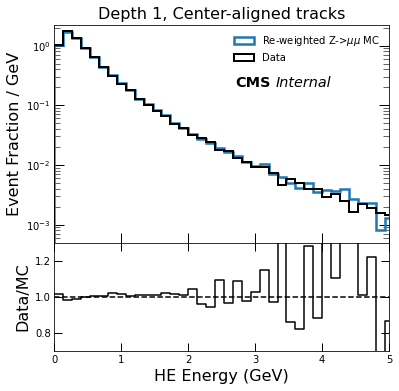

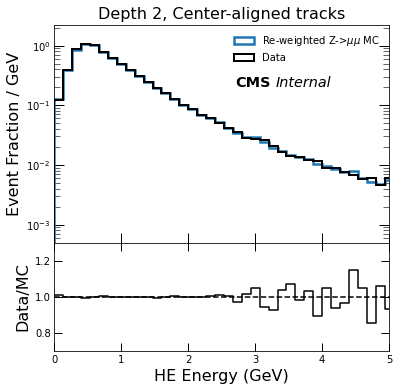

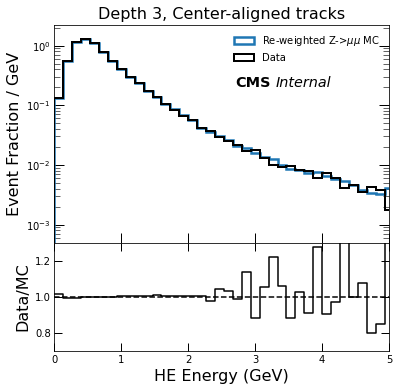

/home/rever025/.local/lib/python3.6/site-packages/ipykernel_launcher.py:18: RuntimeWarning: divide by zero encountered in true_divide


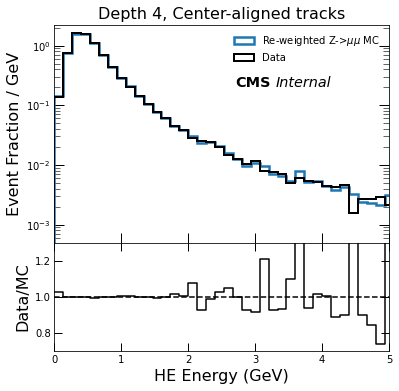

/home/rever025/.local/lib/python3.6/site-packages/ipykernel_launcher.py:18: RuntimeWarning: divide by zero encountered in true_divide


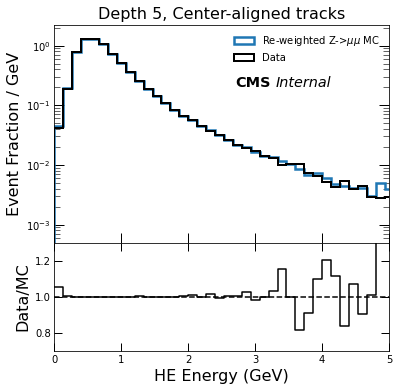

/home/rever025/.local/lib/python3.6/site-packages/ipykernel_launcher.py:18: RuntimeWarning: divide by zero encountered in true_divide


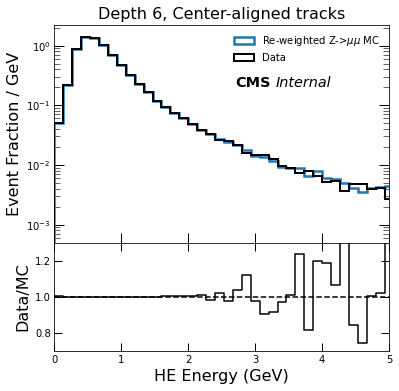

/home/rever025/.local/lib/python3.6/site-packages/ipykernel_launcher.py:18: RuntimeWarning: divide by zero encountered in true_divide
/home/rever025/.local/lib/python3.6/site-packages/ipykernel_launcher.py:18: RuntimeWarning: invalid value encountered in true_divide


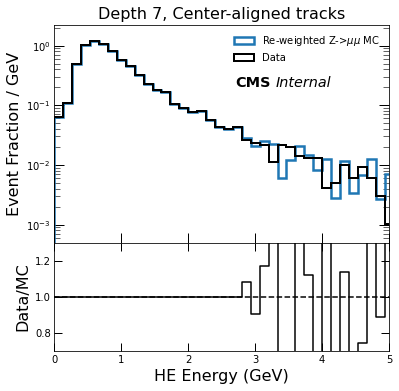

In [320]:
#reweightHist = plt.hist(tagMC['hitEnergiesDepth3'],bins=binsx,density=True,weights=tagMC['EventWeight'],label='reweight',fill=False)
for depth in range(7):
    #noWeightHist = plt.hist(tagMC['hitEnergiesDepth3'],alpha=0.5, density=True, bins=100,label='non-reweight')
    fig, (absolute, ratio) = plt.subplots(
        nrows=2,
        sharex = 'col', # have the columns share the x axis
        gridspec_kw = dict(
            hspace = 0.0, # shrink height space between the two figs
            height_ratios = [2,1]
        )
    )
    fig.set_figheight(6)
    reweightHist = absolute.hist(mc['hitEnergiesDepth'+str(depth)],bins=bins,density=True,label='Re-weighted Z->$\mu\mu$ MC',weights=weights,histtype=u'step',linewidth=2.5)
    dataHist = absolute.hist(data['hitEnergiesDepth'+str(depth)],density=True,bins=bins,label='Data',histtype='step',linewidth=2, color='black')
    absolute.set_yscale('log')
    absolute.set_ylabel('Event Fraction / GeV',fontsize=16)
    absolute.legend()
    ratioHist = reweightHist[0]/dataHist[0]
    ratio.step(bins[:-1],ratioHist,where='post',color='black')
    ratio.set_ylabel('Data/MC',fontsize=16)

    leg=absolute.legend(loc='upper right')
    leg.get_frame().set_alpha(0)
    tx = absolute.text(2.7, 0.2, "CMS", size="x-large",weight='bold')
    tx2 = absolute.text(3.3, 0.2, "Internal", size="x-large",style='italic')
    absolute.tick_params(direction='in', length=10, width=1)
    absolute.tick_params(which='minor', direction='in',length=6)
    absolute.yaxis.set_ticks_position('both')
    absolute.set_title('Depth '+str(depth+1)+', Center-aligned tracks',fontsize=16)
    absolute.set_ylim([0.0005,2.2])
    ratio.set_xlabel('HE Energy (GeV)',fontsize=16)
    ratio.tick_params(direction='in', length=8, width=1)
    ratio.yaxis.set_ticks_position('both')
    ratio.xaxis.set_ticks_position('both')
    ratio.set_xlim([0, 5])
    ratio.set_ylim([0.7,1.3])
    x_points = [0,5]
    y_points = [1, 1]
    ratio.plot(x_points, y_points, 'black',linestyle='dashed')
    plt.savefig("plots/reweightedHcalEnergies_depth"+str(depth+1)+".pdf")
    plt.show()

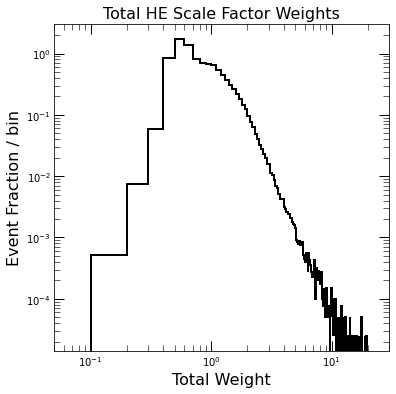

In [321]:
weightBins = [x/10. for x in range(200)]

#noWeightHist = plt.hist(tagMC['hitEnergiesDepth3'],alpha=0.5, density=True, bins=100,label='non-reweight')
fig, weightPlot = plt.subplots(
        nrows=1
    )
fig.set_figheight(6)
dataHist = weightPlot.hist(weights,bins=weightBins,density=True,label='weights',histtype='step',linewidth=2, color='black')
plt.yscale("log")
plt.xscale("log")
plt.title('Total HE Scale Factor Weights',fontsize=16)
plt.xlabel('Total Weight',fontsize=16)
plt.ylabel('Event Fraction / bin',fontsize=16)
plt.tick_params(direction='in', length=10, width=1)
plt.tick_params(which='minor', direction='in',length=6)
weightPlot.yaxis.set_ticks_position('both')
weightPlot.xaxis.set_ticks_position('both')
plt.xlim([0.05,30])
plt.savefig("plots/totalHEWeights.pdf")
plt.show()


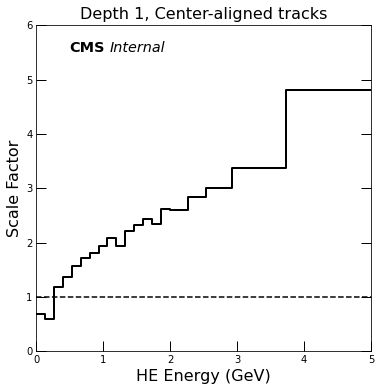

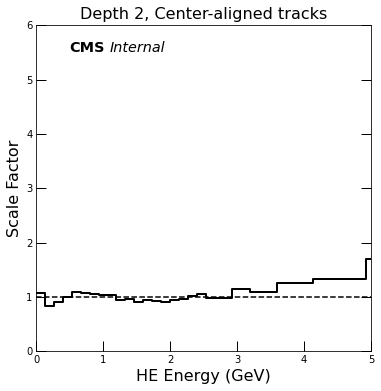

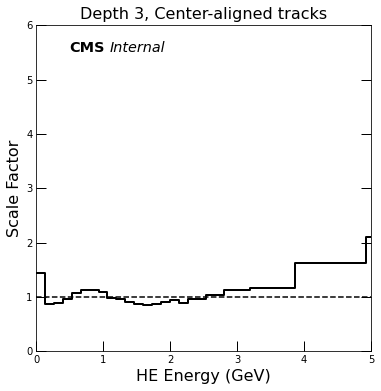

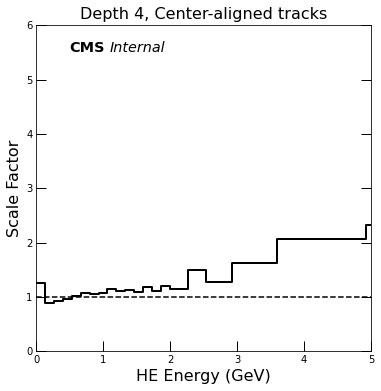

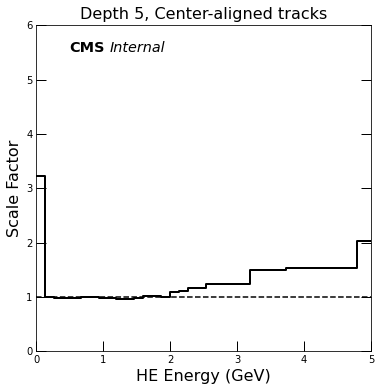

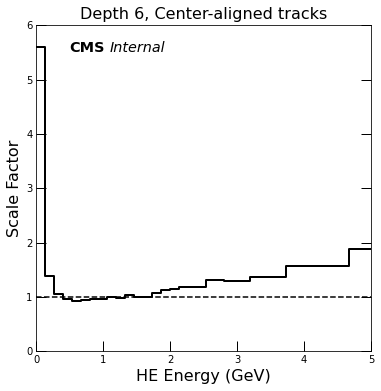

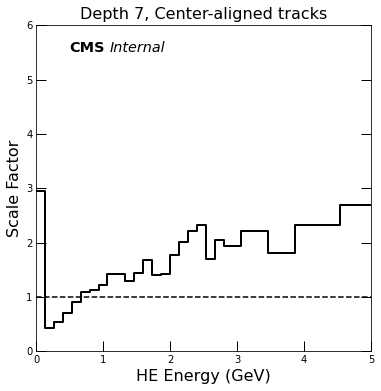

In [322]:
for depth in range(7):
    #noWeightHist = plt.hist(tagMC['hitEnergiesDepth3'],alpha=0.5, density=True, bins=100,label='non-reweight')
    fig, scaleFactor = plt.subplots(
        nrows=1
    )
    fig.set_figheight(6)
    sf = scaleFactor.step(newBinsArr[depth], SFs[depth],where='post',color='black',linewidth=2)
    scaleFactor.set_ylabel('Scale Factor',fontsize=16)

    tx = scaleFactor.text(0.5, 5.5, "CMS", size="x-large",weight='bold')
    tx2 = scaleFactor.text(1.1, 5.5, "Internal", size="x-large",style='italic')
    scaleFactor.set_title('Depth '+str(depth+1)+', Center-aligned tracks',fontsize=16)
    scaleFactor.set_ylim([0.000,6])
    scaleFactor.set_xlabel('HE Energy (GeV)',fontsize=16)
    scaleFactor.set_xlim([0, 5])
    scaleFactor.tick_params(direction='in', length=10, width=1)
    scaleFactor.yaxis.set_ticks_position('both')
    x_points = [0,5]
    y_points = [1, 1]
    scaleFactor.plot(x_points, y_points, 'black',linestyle='dashed')
    plt.savefig("plots/HcalWeights_depth"+str(depth+1)+".pdf")
    plt.show()

In [323]:
import pickle

In [324]:
with open('HcalSFs.pickle', 'wb') as f:
    # Pickle the 'data' dictionary using the highest protocol available.
    pickle.dump([newBinsArr, SFs], f, pickle.HIGHEST_PROTOCOL)